# Problem 7.6: K–R Curve (Compact Specimen)

Assuming all nonlinearity is crack growth, each point's secant compliance $C=\Delta/P$ gives the crack length $a$ (Appendix A7, plane stress $E'=E$). $K_R$ is then the CT solution evaluated at that $a$.

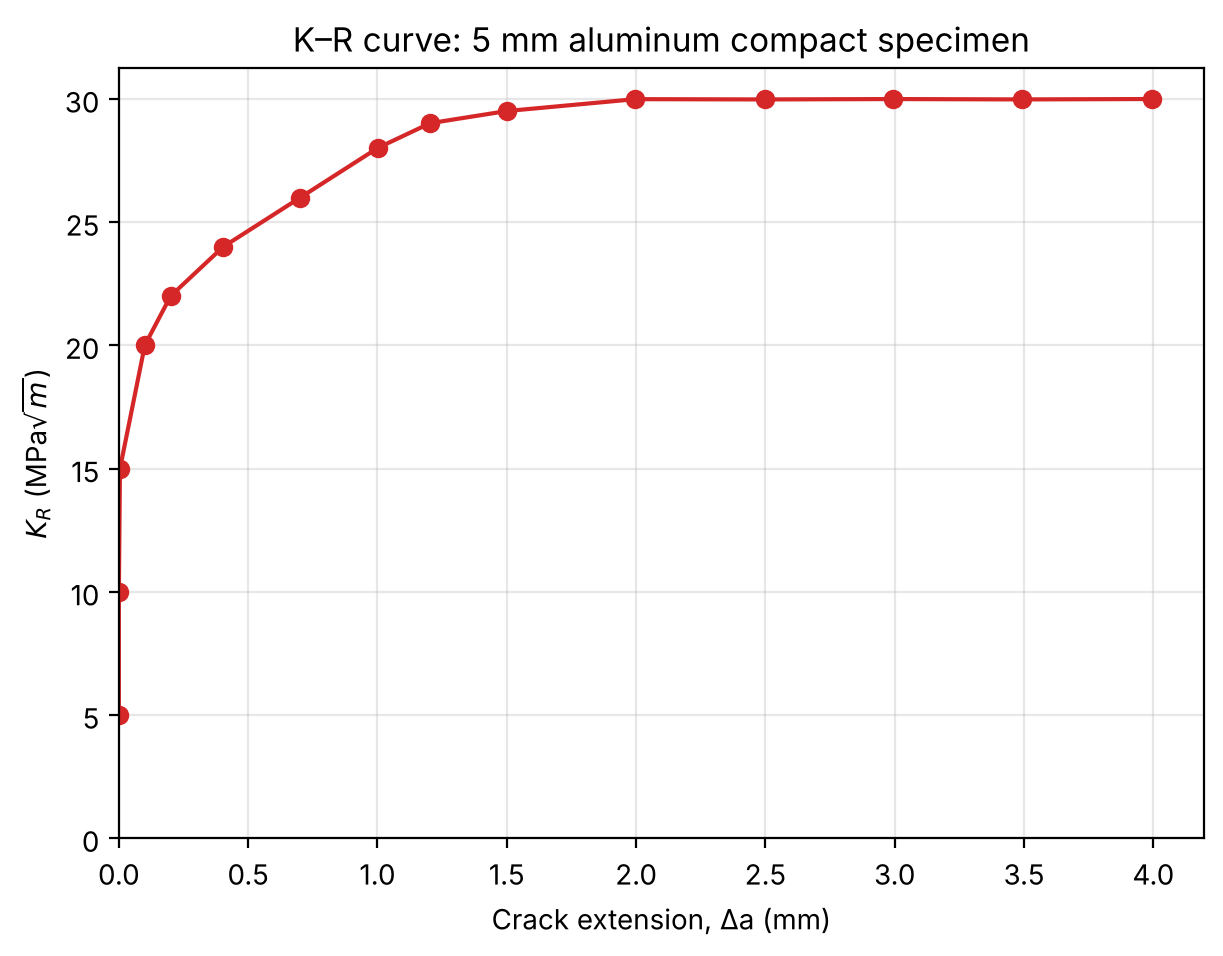

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Specimen / material (N, mm, MPa)
W, B, a0, E = 50.0, 5.0, 26.0, 70_000.0

# Test data
P = 1000 * np.array([0.5433, 1.087, 1.630, 2.161, 2.361, 2.541, 2.699,
                     2.851, 2.913, 2.903, 2.850, 2.749, 2.652, 2.553, 2.457])   # N
disp = np.array([0.0635, 0.1270, 0.1906, 0.2552, 0.2817, 0.3096, 0.3392,
                 0.3698, 0.3860, 0.3971, 0.4113, 0.4191, 0.4274, 0.4355, 0.4443])  # mm

# Crack length from compliance (Appendix A7)
u = 1 / (np.sqrt(B * E * disp / P) + 1)
aW = 1.000196 - 4.06319*u + 11.242*u**2 - 106.043*u**3 + 464.335*u**4 - 650.677*u**5
da = np.clip(aW * W - a0, 0, None)   # mm

# Stress intensity, MPa*sqrt(m)
f = (2 + aW) / (1 - aW)**1.5 * (0.886 + 4.64*aW - 13.32*aW**2 + 14.72*aW**3 - 5.6*aW**4)
K = P / (B * np.sqrt(W)) * f / np.sqrt(1000)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(da, K, 'o-', color='tab:red')
ax.set_xlabel('Crack extension, Δa (mm)')
ax.set_ylabel(r'$K_R$ (MPa$\sqrt{m}$)')
ax.set_title('K–R curve: 5 mm aluminum compact specimen')
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
plt.show()